<a href="https://colab.research.google.com/github/rqhz0618-uol/Statistical-Analysis/blob/main/IMDb_Movie_Data_Analysis_%26_Rating_Prediction_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IMDb Movie Data Analysis and Rating Prediction

By Zikril Hakim Bin Shahrol Hanizam

## Introduction

This project explores a dataset containing 5,000 movies to investigate patterns associated with IMDb movie ratings and popularity.

The project applies data cleaning, exploratory data analysis (EDA), statistical analysis, data visualisation, feature engineering, and machine learning.

### Objectives

The main questions explored are:

- How are IMDb movie ratings distributed?
- Is movie popularity associated with higher IMDb ratings?
- Does movie runtime have a relationship with IMDb rating?
- Have movie ratings changed across different decades?
- Which movie genres tend to receive higher ratings?
- Can machine learning be used to predict IMDb movie ratings?

The final part of the project compares machine learning models to determine how accurately movie ratings can be predicted using available movie characteristics.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Libraries

Three main Python libraries are used throughout this project:

- **Pandas** for data manipulation and analysis.
- **NumPy** for numerical operations.
- **Matplotlib** for data visualisation.

In [ ]:
df = pd.read_csv("/content/results_with_crew.csv")

In [ ]:
df.head()

,tconst,primaryTitle,startYear,rank,averageRating,numVotes,runtimeMinutes,directors,writers,genres,IMDbLink,Title_IMDb_Link
0,tt0111161,The Shawshank Redemption,1994,1,9.3,3221521,142,Frank Darabont,"Stephen King, Frank Darabont",Drama,"<a href=""https://www.imdb.com/title/tt0111161""...","<a href=""https://www.imdb.com/title/tt0111161""..."
1,tt0068646,The Godfather,1972,2,9.2,2245619,175,Francis Ford Coppola,"Francis Ford Coppola, Mario Puzo","Crime, Drama","<a href=""https://www.imdb.com/title/tt0068646""...","<a href=""https://www.imdb.com/title/tt0068646""..."
2,tt0468569,The Dark Knight,2008,3,9.1,3207554,152,Christopher Nolan,"Jonathan Nolan, Christopher Nolan, David S. Go...","Crime, Thriller","<a href=""https://www.imdb.com/title/tt0468569""...","<a href=""https://www.imdb.com/title/tt0468569""..."
3,tt0167260,The Lord of the Rings: The Return of the King,2003,4,9.0,2183069,201,Peter Jackson,"Peter Jackson, J.R.R. Tolkien, Fran Walsh, Phi...","Adventure, Drama, Fantasy","<a href=""https://www.imdb.com/title/tt0167260""...","<a href=""https://www.imdb.com/title/tt0167260""..."
4,tt0108052,Schindler's List,1993,5,9.0,1596665,195,Steven Spielberg,"Steven Zaillian, Thomas Keneally","Biography, Drama, History","<a href=""https://www.imdb.com/title/tt0108052""...","<a href=""https://www.imdb.com/title/tt0108052""..."


## Dataset Overview

The dataset contains information about 5,000 movies, including movie titles, release years, IMDb ratings, number of votes, runtime, genres, directors, and writers.

The dataset is first inspected to understand its structure and identify potential data-quality issues.

In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (5000, 12)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           5000 non-null   object 
 1   primaryTitle     5000 non-null   object 
 2   startYear        5000 non-null   int64  
 3   rank             5000 non-null   int64  
 4   averageRating    5000 non-null   float64
 5   numVotes         5000 non-null   int64  
 6   runtimeMinutes   5000 non-null   int64  
 7   directors        5000 non-null   object 
 8   writers          4975 non-null   object 
 9   genres           5000 non-null   object 
 10  IMDbLink         5000 non-null   object 
 11  Title_IMDb_Link  5000 non-null   object 
dtypes: float64(1), int64(4), object(7)
memory usage: 468.9+ KB


In [ ]:
df.describe()

,startYear,rank,averageRating,numVotes,runtimeMinutes
count,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000
mean,2002.203600,2500.500000,7.183820,1.690308e+05,115.264200
std,18.802001,1443.520003,0.570808,2.555735e+05,23.799968
min,1920.000000,1.000000,6.100000,2.500300e+04,25.000000
25%,1994.000000,1250.750000,6.700000,4.031650e+04,99.000000
50%,2007.000000,2500.500000,7.100000,7.387850e+04,111.000000
75%,2016.000000,3750.250000,7.600000,1.838560e+05,127.000000
max,2026.000000,5000.000000,9.300000,3.221521e+06,374.000000


The dataset contains 5,000 observations and 12 variables.

Initial inspection shows that the numerical variables include release year, IMDb rating, number of votes, and runtime.

The average IMDb rating in the dataset is approximately 7.18, while the ratings range from 6.1 to 9.3.

# Data Cleaning

Before performing analysis, the dataset was checked for duplicate observations, missing values, inappropriate data types, and unusual numerical values.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IMDb IDs:", df["tconst"].duplicated().sum())

Duplicate rows: 0
Duplicate IMDb IDs: 0


No completely duplicated rows or duplicated IMDb identifiers were found, indicating that each observation represents a unique movie.

In [ ]:
df.isnull().sum()

,0
tconst,0
primaryTitle,0
startYear,0
rank,0
averageRating,0
numVotes,0
runtimeMinutes,0
directors,0
writers,25
genres,0


Only 25 missing values were found, all within the `writers` variable.

This represents only 0.5% of the 5,000 observations. Since writer information is not required for the main analysis, these observations were retained rather than unnecessarily removing otherwise useful movie data.

In [ ]:
df.dtypes

,0
tconst,object
primaryTitle,object
startYear,int64
rank,int64
averageRating,float64
numVotes,int64
runtimeMinutes,int64
directors,object
writers,object
genres,object


The important numerical variables were stored using appropriate numerical data types, while variables such as movie title, director, writer, and genre were stored as text-like objects. Therefore, no major data-type conversion was required.

In [ ]:
print("Rating range:",
      df["averageRating"].min(),
      "-",
      df["averageRating"].max())

print("Runtime range:",
      df["runtimeMinutes"].min(),
      "-",
      df["runtimeMinutes"].max())

print("Year range:",
      df["startYear"].min(),
      "-",
      df["startYear"].max())

Rating range: 6.1 - 9.3
Runtime range: 25 - 374
Year range: 1920 - 2026


IMDb ratings range from 6.1 to 9.3, movie runtimes range from 25 to 374 minutes, and release years range from 1920 to 2026.

Although the maximum runtime of 374 minutes initially appeared unusual, further inspection showed that this observation corresponds to *The Best of Youth*. Therefore, the value was retained rather than automatically treating it as incorrect data.

This demonstrates an important distinction between an unusual observation and an erroneous observation.

# Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand the distributions and relationships between important movie characteristics.

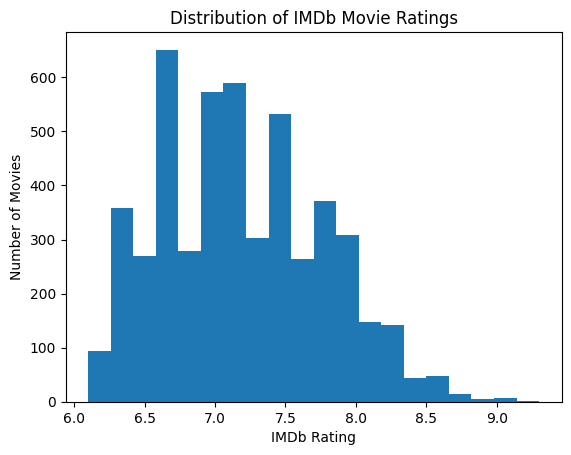

In [ ]:
plt.hist(df["averageRating"], bins=20)

plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")
plt.title("Distribution of IMDb Movie Ratings")

plt.show()

IMDb ratings are concentrated mainly around the 6.5–8.0 range, while extremely highly rated movies are considerably less common.

The average IMDb rating across the dataset is approximately 7.18.

In [ ]:
high_rated = df[df["averageRating"] >= 8.0].shape[0]

high_rated_percentage = high_rated / df.shape[0] * 100

print("Movies rated 8.0 or higher:", high_rated)
print("Percentage:", high_rated_percentage)

Movies rated 8.0 or higher: 561
Percentage: 11.219999999999999


561 movies have an IMDb rating of at least 8.0, representing approximately 11.22% of the dataset.

Therefore, ratings of 8.0 or higher are relatively uncommon within this dataset.

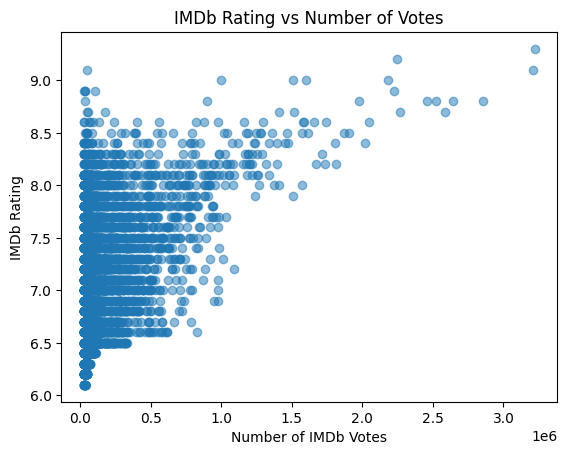

In [ ]:
plt.scatter(df["numVotes"], df["averageRating"], alpha=0.5)

plt.xlabel("Number of IMDb Votes")
plt.ylabel("IMDb Rating")
plt.title("IMDb Rating vs Number of Votes")

plt.show()

The correlation between number of IMDb votes and average rating is approximately **0.39**.

This indicates a moderate positive association, suggesting that movies receiving more IMDb votes tend to have somewhat higher ratings.

However, correlation does not imply causation. A larger number of votes does not necessarily cause a movie to receive a higher rating.

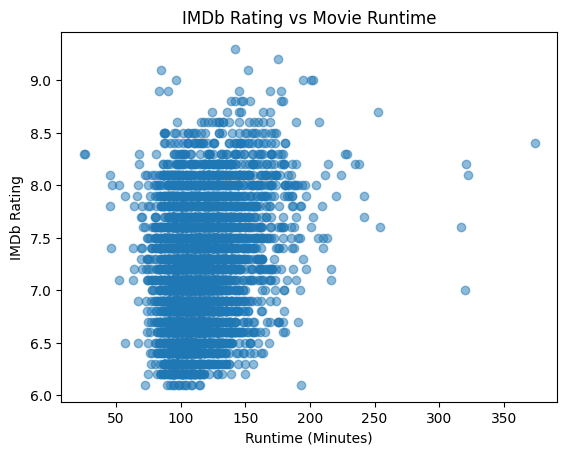

In [ ]:
plt.scatter(df["runtimeMinutes"], df["averageRating"], alpha=0.5)

plt.xlabel("Runtime (Minutes)")
plt.ylabel("IMDb Rating")
plt.title("IMDb Rating vs Movie Runtime")

plt.show()

In [ ]:
runtime_rating_corr = df["runtimeMinutes"].corr(df["averageRating"])

print("Correlation:", runtime_rating_corr)

Correlation: 0.2835721322643407


Runtime and IMDb rating have a correlation of approximately **0.28**, indicating a weak positive relationship.

Longer movies therefore tend to have slightly higher ratings within this dataset, although runtime alone does not appear to be a strong indicator of movie rating.

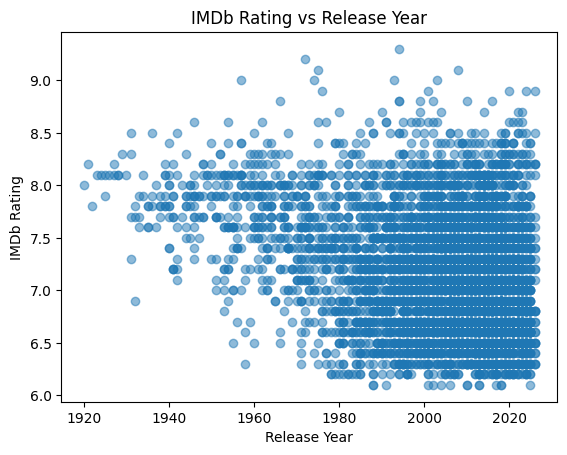

In [ ]:
plt.scatter(df["startYear"], df["averageRating"], alpha=0.5)

plt.xlabel("Release Year")
plt.ylabel("IMDb Rating")
plt.title("IMDb Rating vs Release Year")

plt.show()

In [ ]:
year_rating_corr = df["startYear"].corr(df["averageRating"])

print("Correlation:", year_rating_corr)

Correlation: -0.26722998556729194


Release year has a weak negative correlation with IMDb rating of approximately **-0.27**.

This suggests that newer movies in the dataset tend to have slightly lower ratings. However, this result should be interpreted cautiously because the dataset contains substantially fewer older movies.

In [ ]:
df["decade"] = (df["startYear"] // 10) * 10

In [ ]:
decade_ratings = df.groupby("decade")["averageRating"].mean()

decade_ratings

,averageRating
decade,
1920,8.084615
1930,7.850000
1940,7.806452
1950,7.704808
1960,7.673826
1970,7.422273
1980,7.173381
1990,7.145969
2000,7.154482


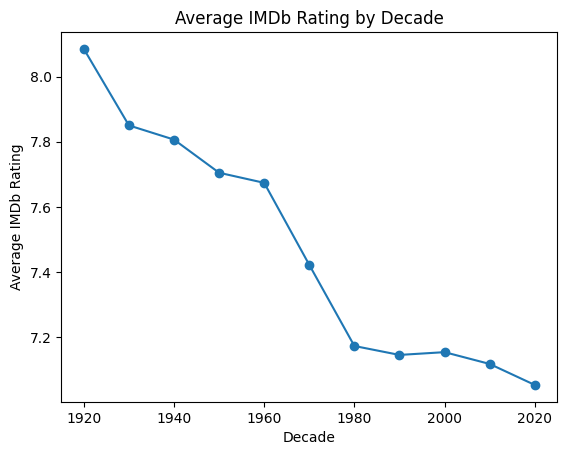

In [ ]:
plt.plot(
    decade_ratings.index,
    decade_ratings.values,
    marker="o"
)

plt.xlabel("Decade")
plt.ylabel("Average IMDb Rating")
plt.title("Average IMDb Rating by Decade")

plt.show()

In [ ]:
df["decade"].value_counts().sort_index()

,count
decade,
1920,13
1930,32
1940,62
1950,104
1960,149
1970,220
1980,417
1990,707
2000,1138


Average IMDb ratings generally decline across more recent decades within the dataset.

However, the sample sizes vary substantially. For example, only 13 movies represent the 1920s, compared with more than 1,400 movies from the 2010s.

Therefore, the apparent decline should not be interpreted as evidence that older movies are inherently better. Selection bias may be present because older movies that remain prominent enough to appear in the dataset may disproportionately represent well-regarded classics.

## Genre Analysis

Movies can belong to multiple genres. Therefore, genre combinations such as `Action,Crime,Drama` were separated so that each individual genre could be analysed independently.

In [ ]:
genre_df = df.copy()

genre_df["genres"] = genre_df["genres"].str.split(",")

genre_df = genre_df.explode("genres")

In [ ]:
genre_stats = genre_df.groupby("genres")["averageRating"].agg(["mean", "count"])

major_genres = (
    genre_stats[genre_stats["count"] >= 100]
    .sort_values("mean", ascending=False)
)

major_genres

,mean,count
genres,,
War,7.540625,128
History,7.316522,230
Drama,7.305410,1072
Biography,7.291874,443
Crime,7.266996,506
Animation,7.244403,268
Adventure,7.235152,495
Music,7.232237,152
Drama,7.225093,2148


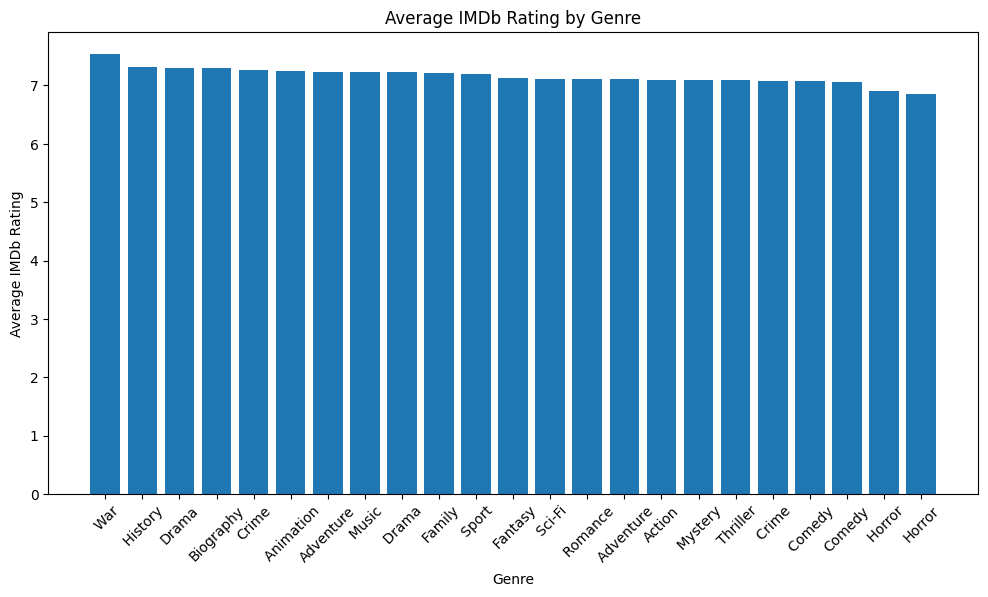

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    major_genres.index,
    major_genres["mean"]
)

plt.xlabel("Genre")
plt.ylabel("Average IMDb Rating")
plt.title("Average IMDb Rating by Genre")

plt.xticks(rotation=45)

plt.show()

Only genres represented by at least 100 movies were included in the comparison.

This restriction reduces the risk of ranking a genre highly based on only a very small number of movies.

The analysis demonstrates that both average rating and sample size should be considered when comparing categorical groups.

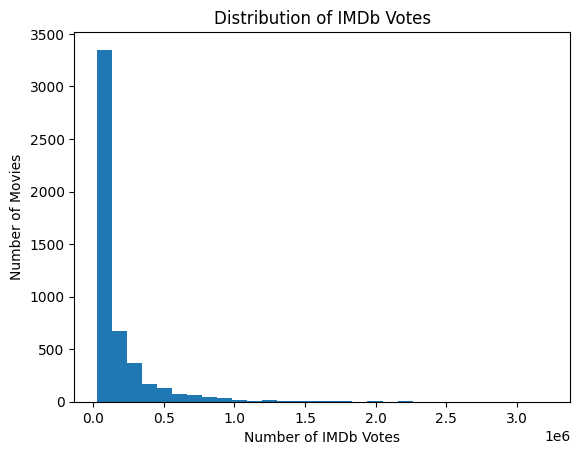

In [ ]:
plt.hist(df["numVotes"], bins=30)

plt.xlabel("Number of IMDb Votes")
plt.ylabel("Number of Movies")
plt.title("Distribution of IMDb Votes")

plt.show()

The number of IMDb votes is strongly right-skewed. Most movies receive substantially fewer votes, while a small number of highly popular movies receive millions of votes.

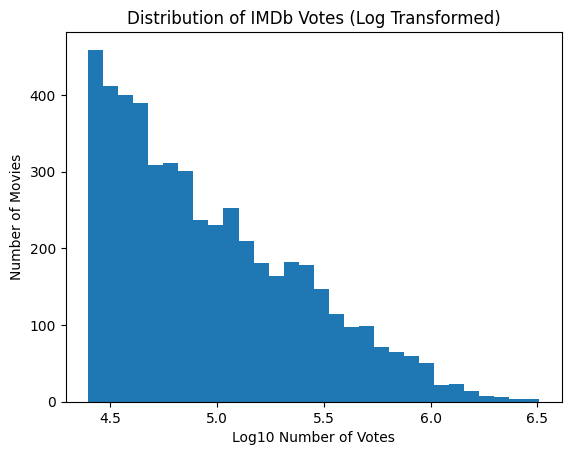

In [ ]:
df["logVotes"] = np.log10(df["numVotes"])

plt.hist(df["logVotes"], bins=30)

plt.xlabel("Log10 Number of Votes")
plt.ylabel("Number of Movies")
plt.title("Distribution of IMDb Votes (Log Transformed)")

plt.show()

A base-10 logarithmic transformation reduces the effect of extremely large vote counts and makes the underlying distribution easier to visualise.

In [ ]:
numeric_df = df[
    ["startYear", "averageRating", "numVotes", "runtimeMinutes"]
]

numeric_df.corr()

,startYear,averageRating,numVotes,runtimeMinutes
startYear,1.000000,-0.267230,0.049548,0.104720
averageRating,-0.267230,1.000000,0.389582,0.283572
numVotes,0.049548,0.389582,1.000000,0.191981
runtimeMinutes,0.104720,0.283572,0.191981,1.000000


The correlation analysis shows that number of votes has the strongest positive relationship with IMDb rating among the numerical variables investigated.

Runtime shows a weaker positive association, while release year has a weak negative association with rating.

These correlations describe associations and should not be interpreted as causal relationships.

# Machine Learning: Predicting IMDb Ratings

The next objective is to investigate whether movie characteristics can be used to predict IMDb ratings.

The target variable is `averageRating`.

The initial model uses three numerical features:

- Release year
- Runtime
- Number of IMDb votes

The dataset is divided into training and testing sets so that model performance can be evaluated using movies that were not used during training.

In [ ]:
X = df[
    ["startYear", "runtimeMinutes", "numVotes"]
]

y = df["averageRating"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 3)
Testing data: (1000, 3)


80% of the dataset is used to train the models, while the remaining 20% is held out for testing.

Using unseen test data provides a more realistic estimate of how well the model may generalise to new observations.

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression R²:", linear_r2)

Linear Regression MAE: 0.4033136667026155
Linear Regression R²: 0.28961430830768964


Model performance is evaluated using two metrics:

- **Mean Absolute Error (MAE):** the average absolute difference between predicted and actual ratings. Lower values indicate better predictions.
- **R²:** measures how much of the variation in IMDb ratings is explained by the model. Higher values generally indicate stronger predictive performance.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [ ]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 0.40388199999999985
Random Forest R²: 0.2605782669639598


## Adding Genre Information

The initial models only use numerical variables.

Genre may contain additional information useful for predicting movie ratings. Since machine learning models cannot directly interpret text categories, genres are converted into binary numerical variables using one-hot encoding.

In [ ]:
genre_encoded = df["genres"].str.get_dummies(sep=",")

genre_encoded.head()

,Adventure,Animation,Biography,Comedy,Crime,Documentary,Drama,Family,Fantasy,Film-Noir,...,Crime,Documentary,Drama,Fantasy,Horror,Mystery,Romance,Sci-Fi,Thriller,Western
0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
X_improved = pd.concat(
    [
        df[["startYear", "runtimeMinutes", "numVotes"]],
        genre_encoded
    ],
    axis=1
)

In [ ]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_improved,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
rf_improved = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_improved.fit(X_train2, y_train2)

rf_pred2 = rf_improved.predict(X_test2)

rf_mae2 = mean_absolute_error(y_test2, rf_pred2)
rf_r2_2 = r2_score(y_test2, rf_pred2)

print("Random Forest + Genres MAE:", rf_mae2)
print("Random Forest + Genres R²:", rf_r2_2)

Random Forest + Genres MAE: 0.3463950000000001
Random Forest + Genres R²: 0.43394164384797873


In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Random Forest + Genres"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        rf_mae2
    ],
    "R²": [
        linear_r2,
        rf_r2,
        rf_r2_2
    ]
})

model_results

,Model,MAE,R²
0,Linear Regression,0.403314,0.289614
1,Random Forest,0.403882,0.260578
2,Random Forest + Genres,0.346395,0.433942


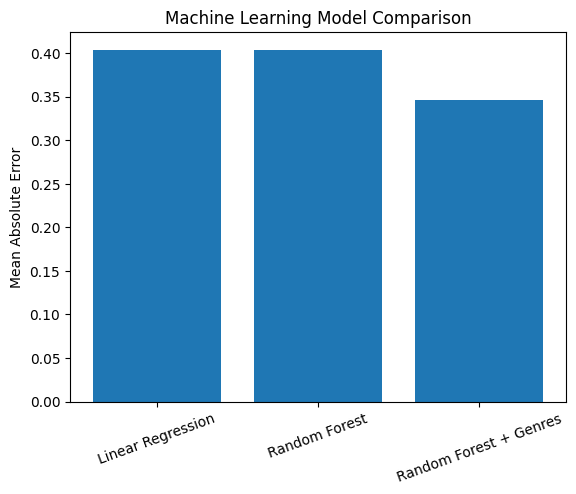

In [ ]:
plt.bar(
    model_results["Model"],
    model_results["MAE"]
)

plt.ylabel("Mean Absolute Error")
plt.title("Machine Learning Model Comparison")

plt.xticks(rotation=20)

plt.show()

# Key Findings

The analysis produced several notable findings:

1. The average IMDb rating within the dataset is approximately **7.18/10**.

2. Only **561 movies (11.22%)** have an IMDb rating of 8.0 or higher.

3. IMDb rating and number of votes have a moderate positive correlation of approximately **0.39**, suggesting that more widely rated movies tend to have somewhat higher ratings.

4. Movie runtime has a weak positive relationship with IMDb rating (**r ≈ 0.28**).

5. Release year has a weak negative relationship with IMDb rating (**r ≈ -0.27**).

6. Older decades appear to have higher average ratings, but these decades contain substantially fewer movies. Therefore, selection bias and unequal sample sizes must be considered.

7. Movie popularity measured through IMDb votes is strongly right-skewed, with a relatively small number of movies receiving millions of votes.

8. Genre comparisons should account for sample size because genres represented by very few movies can produce unreliable average ratings.

9. Machine learning models were able to use movie characteristics to estimate IMDb ratings, with performance evaluated on an unseen test set using MAE and R².

# Limitations

This analysis has several limitations.

First, the dataset contains 5,000 selected movies and therefore should not automatically be considered representative of all movies available on IMDb.

Second, the number of movies differs substantially across decades. Older movies appearing in the dataset may disproportionately represent films that remained popular or highly regarded over time, introducing potential selection bias.

Third, IMDb ratings and vote counts can change over time as additional users rate movies.

The machine learning models are also limited by the available features. Important factors such as budget, box-office performance, cast, awards, production country, and other contextual information are not included.

Finally, correlation between variables does not establish causal relationships.

# Conclusion

This project explored patterns associated with IMDb movie ratings using data cleaning, exploratory data analysis, statistical techniques, data visualisation, feature engineering, and machine learning.

The analysis found that movie popularity had a stronger relationship with IMDb rating than runtime or release year. Ratings also appeared to vary across decades and genres, although differences in sample size and potential selection bias must be considered when interpreting these patterns.

Machine learning models were developed to investigate whether movie characteristics could predict IMDb ratings. Linear Regression provided a baseline model, while Random Forest was used to capture potentially more complex relationships. Genre information was subsequently encoded and incorporated as additional predictive features.

Overall, the project demonstrates how raw movie data can be transformed into meaningful insights while highlighting the importance of careful interpretation, model evaluation, and recognising limitations within a dataset.